# Radio occultation retrieval

This notebook and `ro.py` hold the same code. It follows the CDAAC "Standard RO Inversions in the Neutral Atmosphere 2013-2020" steps
(Sokolovskiy) and gets the ionosphere electron density from L1 and L2. It reads CDAAC netcdf files:
`atmPhs` (COSMIC-1), `conPhs` (COSMIC-2) and `ionPhs`, and compares the result with the CDAAC `atmPrf` and `ionPrf` profiles.

Folders next to this file:
`data` COSMIC-1 atmPhs + atmPrf, `data_cosmic2` COSMIC-2 conPhs + atmPrf, `data_iono` COSMIC-1 ionPhs + ionPrf,
`data_geoid` EGM96 geoid grid (without it heights stay above the ellipsoid).

**Steps done:** 1 straight line height, 2 rising occultations, 3 Fresnel window, 4 Doppler model, 5 open loop detection,
6 open loop navigation bit removal, 7 L2 replaced where it is not tracked, 8 optimal L4 window, 9 filtering, 10 truncation,
11-17 position, azimuth, curvature, bending angle, 18 (simplified), 19 L2 quality (Zeng 2016), 20 wave optics, 21 grid,
22 wave optics merged with geometric optics, 23 Zeng 2016 extrapolation, 24 ionosphere correction, 25 lat/lon/azimuth profiles,
26 first guess and fit, 27 Abel, 28 geoid (EGM96 instead of JGM-2), 29 dry pressure and temperature, QC tests 1-7,
tropopause scalars, ionosphere electron density.

**Not done:** error estimate (local spectral width), boundary layer and sporadic E scalars, 2020 updates 3, 4, 8, 9, 11, 12.
Step 26.3.4 is left out on purpose: with one global standard atmosphere as first guess it made 30-40 km worse.

**Results against CDAAC (medians):** position and azimuth within 0.07 degrees. COSMIC-1 (4 profiles): N within 0.3 % and T within 0.5 K
from 0 to 20 km. COSMIC-2 (8 profiles): N within 0.6 % from 5 to 30 km, at 0-5 km 6 of 8 are within 1 % and 2 K (G32 -2.1 %, G30 -5.3 %).
Tropopause cold point within 0.1 km for 11 of 12 profiles. Ionosphere peak height within 5 km for all 8 profiles.

**Limits:** one global climatology (T is 1 to 7 K high at 30-40 km, QC test 3 can fail by mistake at high latitude),
the open loop tracker can make a wrong decision where the signal is weak, the ionosphere part needs L1 and L2
(CTS-SAT-1 has L1 only, CTS-SAT-2 has L1/L2), and CTS-SAT data will need a reader for the receiver logs.

In [1]:
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import CubicSpline
from scipy.io import netcdf_file
from scipy.optimize import curve_fit
from scipy.signal import savgol_filter

warnings.filterwarnings(
    "ignore", category=RuntimeWarning
)  # nan warnings are expected for bad samples

# folder of this file, the data folders are next to it
FOLDER = Path(__file__).parent if "__file__" in globals() else Path.cwd()

F1 = 1575.42e6  # GPS L1 frequency, Hz
F2 = 1227.60e6  # GPS L2 frequency, Hz
KION = F2**2 / (F1**2 - F2**2)  # ionosphere free combination factor
KTEC = 40.3 * (
    1 / F2**2 - 1 / F1**2
)  # metres of L1 minus L2 phase per electron per m^2
LAMBDA1 = 299792458.0 / F1  # L1 wavelength, m
A_E = 6378137.0  # WGS84 equatorial radius, m
E2 = 6.69437999014e-3  # WGS84 eccentricity squared
R_DRY = 287.06  # gas constant of dry air, J/kg/K
K1 = 77.6  # dry refractivity constant, K/hPa
J2000 = 630763200  # 2000-01-01 12:00 in seconds since the GPS start

## Basic helpers
Vectors are arrays of shape (3, n), so `tx[:, i]` is sample i. Heights are in m, phases in m, angles in rad.

In [2]:
def dot(a, b):
    return np.sum(a * b, axis=0)


def norm(a):
    return np.sqrt(dot(a, a))


def unit(a):
    return a / norm(a)


def cross(a, b):
    return np.cross(a, b, axis=0)


def angle(a, b):
    return np.arctan2(norm(cross(a, b)), dot(a, b))


def read_nc(path):
    f = netcdf_file(path, "r", mmap=False)
    variables = {name: f.variables[name].data.astype(float) for name in f.variables}
    attributes = dict(f._attributes)  # noqa: SLF001
    f.close()
    return variables, attributes


def leap_seconds(year, month):
    # GPS minus UTC, the table gives the date each value starts
    for y, m, s in [
        (2017, 1, 18),
        (2015, 7, 17),
        (2012, 7, 16),
        (2009, 1, 15),
        (2006, 1, 14),
    ]:
        if (year, month) >= (y, m):
            return s
    return 13


def geodetic(pos):
    # latitude (rad), longitude (rad) and height (m) above the WGS84 ellipsoid
    x, y, z = pos
    p = np.hypot(x, y)
    lat = np.arctan2(z, p * (1 - E2))
    for _ in range(6):
        n = A_E / np.sqrt(1 - E2 * np.sin(lat) ** 2)
        lat = np.arctan2(z + E2 * n * np.sin(lat), p)
    n = A_E / np.sqrt(1 - E2 * np.sin(lat) ** 2)
    h = p * np.cos(lat) + z * np.sin(lat) - n * (1 - E2 * np.sin(lat) ** 2)
    return lat, np.arctan2(y, x), h


def bisect(f, lo, hi):
    # bisection for many roots at once, nan where f does not change sign
    f_lo = f(lo)
    bad = np.sign(f_lo) == np.sign(f(hi))
    for _ in range(50):
        mid = 0.5 * (lo + hi)
        same = np.sign(f(mid)) == np.sign(f_lo)
        lo = np.where(same, mid, lo)
        hi = np.where(same, hi, mid)
    return np.where(bad, np.nan, 0.5 * (lo + hi))


def smooth(x, window):
    # step 9: 3rd order Savitzky-Golay filter applied 3 times
    for _ in range(3):
        x = savgol_filter(x, window, 3)
    return x


def blend(low, high, h, h1, h2):
    # smooth switch from "low" below h1 to "high" above h2
    w = np.clip((h - h1) / (h2 - h1), 0, 1)
    w = 0.5 - 0.5 * np.cos(np.pi * w)
    return np.where(w == 0, low, np.where(w == 1, high, (1 - w) * low + w * high))

## Geoid and climatology
Step 28 uses the EGM96 geoid. The first guess (step 26) and the Doppler model (step 4) use the US Standard Atmosphere 1976.

In [3]:
def read_geoid():
    # EGM96 geoid heights in m on a 15 arcminute grid (GeographicLib pgm file), used instead of JGM-2
    path = FOLDER / "data_geoid" / "egm96-15.pgm"
    if not path.exists():
        return None
    raw = path.read_bytes()
    offset = float(re.search(rb"Offset (\S+)", raw).group(1))
    scale = float(re.search(rb"Scale (\S+)", raw).group(1))
    grid = np.frombuffer(raw[-2 * 721 * 1440 :], dtype=">u2").reshape(721, 1440)
    return offset + scale * grid.astype(float)


GEOID = read_geoid()


def geoid_height(lat, lon):
    # bilinear interpolation, lat and lon in degrees, 0 if there is no grid file
    if GEOID is None:
        return 0.0
    row = (90 - lat) / 0.25
    col = (lon % 360) / 0.25
    r0, c0 = min(int(row), 719), int(col) % 1440
    c1 = (c0 + 1) % 1440
    fr, fc = row - r0, col - int(col)
    return (
        (1 - fr) * (1 - fc) * GEOID[r0, c0]
        + (1 - fr) * fc * GEOID[r0, c1]
        + fr * (1 - fc) * GEOID[r0 + 1, c0]
        + fr * fc * GEOID[r0 + 1, c1]
    )


def climatology():
    # US Standard Atmosphere 1976, dry, turned into bending angle by a forward Abel integral
    # returns impact height (m), log of bending angle, height (m) and refractivity
    R = 6371e3
    z = np.arange(0, 150e3 + 1, 100.0)
    T = np.interp(
        z,
        [0, 11e3, 20e3, 32e3, 47e3, 51e3, 71e3, 86e3],
        [288.15, 216.65, 216.65, 228.65, 270.65, 270.65, 214.65, 186.95],
    )
    g = 9.80665 * (R / (R + z)) ** 2
    P = 1013.25 * np.exp(-cumulative_trapezoid(g / (R_DRY * T), z, initial=0))
    n = 1 + 1e-6 * K1 * P / T
    x = n * (R + z)
    dlnn = np.gradient(np.log(n), x)
    alpha = np.zeros(len(x) - 1)
    for k in range(len(x) - 1):
        s = np.sqrt((x[k:] - x[k]) * (x[k:] + x[k]))
        alpha[k] = -2 * x[k] * np.trapezoid(dlnn[k:] / x[k:], s)
    return x[:-1] - R, np.log(alpha), z, (n - 1) * 1e6


CLIM_H, CLIM_LOG_ALPHA, CLIM_Z, CLIM_N = climatology()


def clim_bending(h):
    # climatology bending angle (rad) at impact height h (m)
    return np.exp(np.interp(h, CLIM_H, CLIM_LOG_ALPHA))

## Geometry
Steps 4, 11, 12 and 14: the ray through the climatology, the tangent point, the azimuth and the local curvature of the ellipsoid.

In [4]:
def limb_point(tx, rx):
    # point of the straight line TX-RX closest to the earth center
    u = unit(rx - tx)
    return tx - dot(tx, u) * u


def ray_directions(p, tx, rx):
    # unit vectors of the ray leaving TX and arriving at RX for impact parameter p (Bouguer rule, n = 1 at the satellites)
    rt, rr = norm(tx), norm(rx)
    ut, ur = tx / rt, rx / rr
    ht = unit(rx - dot(rx, ut) * ut)
    hr = unit(tx - dot(tx, ur) * ur)
    gt, gr = np.arcsin(p / rt), np.arcsin(p / rr)
    return -np.cos(gt) * ut + np.sin(gt) * ht, np.cos(gr) * ur - np.sin(gr) * hr


def climate_ray(tx, rx):
    # step 4.1: impact parameter of the ray through the climatology, and the earth radius under the line
    limb = limb_point(tx, rx)
    r0 = norm(limb) - geodetic(limb)[2]
    rt, rr = norm(tx), norm(rx)

    def misfit(p):
        return (
            np.arcsin(p / rt)
            + np.arcsin(p / rr)
            + angle(tx, rx)
            - np.pi
            - clim_bending(p - r0)
        )

    return bisect(misfit, r0, rr - 1), r0


def doppler_model(tx, rx, vtx, vrx):
    # step 4.2: excess Doppler (m/s) of the ray through the climatology, for every sample
    kt, kr = ray_directions(climate_ray(tx, rx)[0], tx, rx)
    return dot(vrx, kr) - dot(vtx, kt) - dot(vrx - vtx, unit(rx - tx))


def occultation_point(tx, rx):
    # steps 11 and 12: tangent point latitude, longitude (inertial) and azimuth
    p, r0 = climate_ray(tx, rx)
    rr = norm(rx)
    up = unit(rx)
    toward_tx = unit(tx - dot(tx, up) * up)
    phi = np.arccos(p / rr) + clim_bending(p - r0) / 2
    tangent = p * (np.cos(phi) * up + np.sin(phi) * toward_tx)
    lat, lon, _ = geodetic(tangent)
    # azimuth from north of the horizontal direction toward TX, same as CDAAC
    horizontal = unit(cross(tangent, unit(cross(tx, rx))))
    east = np.array([-np.sin(lon), np.cos(lon), np.zeros_like(lon)])
    north = np.array(
        [-np.sin(lat) * np.cos(lon), -np.sin(lat) * np.sin(lon), np.cos(lat)]
    )
    return lat, lon, np.arctan2(dot(horizontal, east), dot(horizontal, north))


def curvature(lat, lon, azimuth):
    # step 14: radius and center of local curvature of the ellipsoid along the azimuth
    s = np.sin(lat)
    n = A_E / np.sqrt(1 - E2 * s**2)
    m = A_E * (1 - E2) / (1 - E2 * s**2) ** 1.5
    rc = 1 / (np.cos(azimuth) ** 2 / m + np.sin(azimuth) ** 2 / n)
    up = np.array([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), s])
    surface = np.array(
        [n * np.cos(lat) * np.cos(lon), n * np.cos(lat) * np.sin(lon), n * (1 - E2) * s]
    )
    return rc, surface - rc * up

## Reading the files and the open loop phase
Steps 5, 6 and 7. The COSMIC-1 open loop L1 phase has random half cycle jumps (navigation bits). Each sample is moved by a multiple of
half a wavelength to the value nearest to a quadratic fit of the 24 samples before it. L2 is not tracked in open loop, so it is
replaced by L1 minus the last closed loop difference.

In [5]:
def remove_nav_bits(L, start, step):
    # step 6: the open loop L1 phase has random half cycle jumps (navigation bits)
    # from "start" in direction "step" each sample is moved by a multiple of half a wavelength
    # to the value nearest to a quadratic fit of the 24 corrected samples before it
    half = LAMBDA1 / 2
    out = L.copy()
    for i in range(start, len(L) if step > 0 else -1, step):
        before = out[max(i - 24, 0) : i] if step > 0 else out[i + 1 : i + 25][::-1]
        if len(before) < 3:
            continue
        pred = np.polyval(np.polyfit(np.arange(len(before)), before, 2), len(before))
        out[i] = L[i] - half * np.round((L[i] - pred) / half)
    return out


def read_phase(path):
    # reads an atmPhs (COSMIC-1), conPhs (COSMIC-2) or ionPhs file, positions in m, velocities in m/s, phases in m
    v, at = read_nc(path)
    t = v["time"]
    open_loop, l2_ok = False, True
    if "conPhs" in Path(path).name:
        # orbits come about once per second, the GNSS position is at the transmit time
        ot = v["orbtime"]
        t_abs = at["startTime"] + t
        leo = [CubicSpline(ot, v[k + "LeoLR"]) for k in "xyz"]
        gnss = [CubicSpline(v["txmitLR"], v[k + "GnssLR"]) for k in "xyz"]
        t_tx = CubicSpline(ot, v["txmitLR"])(t_abs)
        tx = np.array([f(t_tx) for f in gnss]) * 1e3
        rx = np.array([f(t_abs) for f in leo]) * 1e3
        vtx = np.array([f.derivative()(t_tx) for f in gnss]) * 1e3
        vrx = np.array([f.derivative()(t_abs) for f in leo]) * 1e3
        good = (v["exL1"] != -999) & (v["exL2"] != -999)
        open_loop = True
    else:
        tx = np.array([v["xGps"], v["yGps"], v["zGps"]]) * 1e3
        rx = np.array([v["xLeo"], v["yLeo"], v["zLeo"]]) * 1e3
        vtx = np.array([v["xdGps"], v["ydGps"], v["zdGps"]]) * 1e3
        vrx = np.array([v["xdLeo"], v["ydLeo"], v["zdLeo"]]) * 1e3
        good = (v["exL1"] != -999) & (v["exL2"] != -999)
        if "xmdl" in v and (v["xmdl"] != -999).any():
            # step 5: samples with a receiver model (xmdl) are open loop
            # step 6: clean the L1 phase, L2 is not tracked there so step 7 uses L1 minus the last closed loop difference
            open_loop = True
            ol = v["xmdl"] != -999
            h_line = geodetic(limb_point(tx, rx))[2]
            setting = h_line[0] > h_line[-1]
            start, step = (
                (int(np.argmax(ol)), 1)
                if setting
                else (len(ol) - 1 - int(np.argmax(ol[::-1])), -1)
            )
            L1 = remove_nav_bits(v["exL1"], start, step)
            l2_ok = (~ol).sum() >= 100
            diff = (v["exL1"] - v["exL2"])[~ol][-1 if setting else 0] if l2_ok else 0.0
            v["exL2"] = np.where(ol, L1 - diff, v["exL2"])
            v["exL1"] = L1
            good = v["exL1"] != -999
    leap = (
        v["leapsec"][0]
        if "leapsec" in v
        else leap_seconds(int(at["year"]), int(at["month"]))
    )
    return {
        "t": t,
        "tx": tx,
        "rx": rx,
        "vtx": vtx,
        "vrx": vrx,
        "L1": v["exL1"],
        "L2": v["exL2"],
        "snr": v["caL1Snr"],
        "good": good,
        "start": at["startTime"],
        "leap": leap,
        "rate": 1 / np.median(np.diff(t)),
        "open_loop": open_loop,
        "l2_ok": l2_ok,
    }

## Filter windows, truncation and L2 quality
Steps 3, 8, 10 and 19. The L2 criterion is from Zeng et al. 2016: L2 is good while the L1 and L2 phase steps differ by less than 6 cm
between 50 Hz samples.

In [6]:
def fresnel_window(t, tx, rx, rate):
    # step 3: samples one Fresnel scale takes, at the sample where the straight line is at 0 km
    limb = limb_point(tx, rx)
    h = geodetic(limb)[2]
    i = np.argmin(np.abs(h))
    samples = (
        np.sqrt(LAMBDA1 * norm(limb[:, i] - rx[:, i]))
        / abs(np.gradient(h, t)[i])
        * rate
    )
    return max(5, 2 * int(samples // 2) + 1)  # odd, the filter needs that


def truncate_closed_loop(diff_hz):
    # step 10.1: from the top find where the Doppler minus the model goes above 10 Hz, then back to where it is below 5 Hz
    above = np.nonzero(np.abs(diff_hz) > 10)[0]
    if len(above) == 0:
        return len(diff_hz)
    i = above[0]
    while i > 0 and np.abs(diff_hz[i]) >= 5:
        i -= 1
    return i


def truncate_snr(snr, rate):
    # step 10.2 for open loop: SNR averaged over 1.5 s, the lowest value is the noise level
    w = int(1.5 * rate)
    f = np.convolve(np.pad(snr, w // 2, mode="edge"), np.ones(w) / w, mode="valid")[
        : len(snr)
    ]
    low = f.min()
    anchor = (
        len(f) - 1 - np.argmax(f[::-1] > 3 * low)
    )  # from the bottom, first value above 3 times the noise
    below = np.nonzero(f[: anchor + 1] < 1.5 * low)[
        0
    ]  # from the top, first value below 1.5 times the noise
    i = below[0] if len(below) else anchor
    while i + 1 < len(f) and f[i + 1] < f[i]:  # then follow it while it drops
        i += 1
    return i


def optimal_window(t, line_h, L1, L2, win1, win2):
    # step 8: window for L4 = L1 - L2 between win1 and win2 that makes the LC Doppler quietest at 60-80 km
    m = (line_h >= 60e3) & (line_h <= 80e3)
    if m.sum() < 3 * win2:
        return win2
    big = min(2 * win2 + 1, 2 * ((len(t) - 1) // 2) - 1)
    best, best_std = win2, np.inf
    for w in range(win1, win2 + 1, 2):
        lc = np.gradient(smooth(L1, win1) + KION * smooth(L1 - L2, w), t)
        s = np.std((lc - smooth(lc, big))[m])
        if s < best_std:
            best, best_std = w, s
    return best


def l2_bad_height(line_h, L1, L2, rate):
    # step 19, criterion of Zeng et al. 2016: L2 is good while the L1 and L2 phase steps differ by less than 6 cm
    # between 50 Hz samples. Returns the highest height below 40 km where that fails, 0 if it never fails.
    step = np.abs(np.diff(L1) - np.diff(L2)) * (rate / 50)
    bad = (step > 0.06) & (line_h[:-1] < 40e3)
    return line_h[:-1][bad].max() if bad.any() else 0.0

## Bending angle
Steps 17 and 18: find the ray whose Doppler matches the measured excess phase rate, and keep samples where the impact parameter keeps falling.

In [7]:
def bending_angle(rate, tx, rx, vtx, vrx):
    # step 17: find the ray whose Doppler matches the measured excess phase rate (m/s)
    u = unit(rx - tx)
    rt, rr = norm(tx), norm(rx)
    measured = dot(vrx - vtx, u) + rate

    def misfit(p):
        kt, kr = ray_directions(p, tx, rx)
        return dot(vrx, kr) - dot(vtx, kt) - measured

    p_line = norm(cross(tx, u))
    p = bisect(misfit, p_line - 2e3, np.minimum(p_line + 150e3, np.minimum(rt, rr) - 1))
    return p, np.arcsin(p / rt) + np.arcsin(p / rr) + angle(tx, rx) - np.pi


def to_grid(p, alpha, grid):
    # step 18: keep samples where p keeps going down, then interpolate to the grid
    ok = np.isfinite(p)
    p, alpha = p[ok], alpha[ok]
    keep = p < np.minimum.accumulate(np.r_[np.inf, p[:-1]])
    return np.interp(grid, p[keep][::-1], alpha[keep][::-1], left=np.nan, right=np.nan)

## Wave optics
Steps 20 and 22. The L1 signal is transformed from time to impact parameter (phase matching), and the bending angle comes from the
frequency of the transformed signal. Two points matter: the impact parameter is not dL/dtheta because GPS moves radially
(25 to 40 m/s), and the range rate must come from the velocities.

In [8]:
def wave_optics(t, tx, rx, vtx, vrx, L1, amp, win1, rc):
    # steps 20.1-20.4: phase matching. The L1 signal is transformed from time to impact parameter,
    # the bending angle comes from the frequency of the transformed signal.
    # tx and rx are relative to the curvature center, amp is the signal amplitude
    k = 2 * np.pi / LAMBDA1
    n = len(L1)
    theta = angle(tx, rx)
    r_t, r_r = norm(tx), norm(rx)
    L = norm(rx - tx) + L1 - L1[0]  # total phase path
    dtheta = np.abs(np.gradient(theta))

    # dL/dtheta is not the impact parameter when the satellites move radially (GPS does, 25 to 40 m/s), so
    # p = (dL/dt - cos(gt) * dr_t/dt - cos(gr) * dr_r/dt) / dtheta/dt
    # the range rate comes from the velocities, smoothing the range gives a wrong rate when sample times are uneven
    dL = dot(vrx - vtx, unit(rx - tx)) + np.gradient(smooth(L1, win1), t)
    dth, drt, drr = (np.gradient(x, t) for x in (theta, r_t, r_r))
    p_pseudo = dL / dth
    p_s = p_pseudo.copy()
    for _ in range(3):
        p_s = (
            dL
            - np.sqrt(1 - (p_s / r_t) ** 2) * drt
            - np.sqrt(1 - (p_s / r_r) ** 2) * drr
        ) / dth
    for x in (p_pseudo, p_s):  # fill bad samples from their neighbours
        good = np.isfinite(x)
        if good.sum() < 10:
            return None
        x[~good] = np.interp(np.nonzero(~good)[0], np.nonzero(good)[0], x[good])
    p_pseudo, p_s = (
        smooth(p_pseudo, 3 * win1),
        smooth(p_s, 3 * win1),
    )  # only used to find where each p is
    keep = p_s < np.minimum.accumulate(np.r_[np.inf, p_s[:-1]])

    # step 20.1: impact height grid with 1 m step, 0 to 21 km
    h = np.arange(0, 21e3 + 1, 1.0)
    p = rc + h
    index = np.interp(
        p, p_s[keep][::-1], np.arange(n)[keep][::-1], left=np.nan, right=np.nan
    )
    valid = np.isfinite(index)
    if valid.sum() < 1000:
        return None
    p_tilde = np.where(
        valid, np.interp(index, np.arange(n), p_pseudo), p
    )  # the grid in the variable of the transform

    # step 20.2.1: for each p add up the samples whose own impact parameter is within 2 km of it (cos^2 weight)
    # around the main stationary sample, so slow moving p (defocusing) gives many samples
    dp_max = 2000.0
    cap = 40 * win1
    seg_lo, seg_hi = (
        np.minimum(p_pseudo[:-1], p_pseudo[1:]),
        np.maximum(p_pseudo[:-1], p_pseudo[1:]),
    )
    U = np.zeros(len(p), complex)
    start_phase = np.zeros(len(p))
    index = np.full(len(p), np.nan)
    for m in np.nonzero(valid)[0]:
        pt = p_tilde[m]
        crossing = np.nonzero((seg_lo <= pt) & (seg_hi >= pt))[0]
        if len(crossing) == 0:
            continue
        i0 = crossing[
            np.argmax(L[crossing] - pt * theta[crossing])
        ]  # main stationary sample
        a, b = max(i0 - cap, 0), min(i0 + cap, n - 1)
        out = np.abs(p_pseudo[a : b + 1] - pt) >= dp_max
        left, right = np.nonzero(out[: i0 - a])[0], np.nonzero(out[i0 - a :])[0]
        i = np.arange(
            a + left[-1] + 1 if len(left) else a, i0 + right[0] if len(right) else b + 1
        )
        w = np.cos(0.5 * np.pi * (p_pseudo[i] - pt) / dp_max) ** 2
        psi = k * ((L[i] - L[i0]) - pt * (theta[i] - theta[i0]))
        U[m] = np.sum(w * amp[i] * dtheta[i] * np.exp(1j * psi))
        start_phase[m] = k * (L[i0] - pt * theta[i0])
        step = p_pseudo[i0 + 1] - p_pseudo[i0]
        index[m] = i0 + (pt - p_pseudo[i0]) / step if step != 0 else i0
    valid = np.isfinite(index)

    # take out the fast phase of the stationary sample, the rest changes slowly with p
    theta_ref = np.where(valid, np.interp(index, np.arange(n), theta), 0.0)
    V = U * np.exp(
        1j * (start_phase + k * cumulative_trapezoid(theta_ref, p_tilde, initial=0))
    )
    ok = np.nonzero(valid & np.isfinite(V))[0]
    if len(ok) < 1000:
        return None
    phase = np.unwrap(np.angle(V[ok]))
    theta_star = (
        theta_ref[ok] - np.gradient(savgol_filter(phase, 101, 3), p_tilde[ok]) / k
    )
    r_t_star = np.interp(index[ok], np.arange(n), r_t)
    r_r_star = np.interp(index[ok], np.arange(n), r_r)
    alpha = np.full(len(p), np.nan)
    alpha[ok] = (
        np.arcsin(p[ok] / r_t_star) + np.arcsin(p[ok] / r_r_star) + theta_star - np.pi
    )

    # step 20.3: low pass with 100, 225 and 500 m windows, merged at 7 and 10 km with 1 km transitions
    def low_pass(width):
        out = np.full(len(p), np.nan)
        out[ok] = smooth(alpha[ok], min(width, 2 * ((len(ok) - 1) // 2) - 1))
        return out

    alpha = blend(
        blend(low_pass(101), low_pass(225), h, 6.5e3, 7.5e3),
        low_pass(501),
        h,
        9.5e3,
        10.5e3,
    )

    # step 20.4: truncate at the lowest height where the amplitude is above half of its mean at 10-20 km
    amp_u = np.abs(U) / np.mean(np.abs(U)[(h >= 10e3) & (h <= 20e3)])
    amp_u = np.convolve(
        np.pad(amp_u, 100, mode="edge"), np.ones(201) / 201, mode="valid"
    )
    above = np.nonzero(amp_u > 0.5)[0]
    if len(above) == 0:
        return None
    alpha[h < h[above[0]]] = np.nan
    return h, alpha, h[above[0]]

## Quality control, ionosphere extrapolation, Abel inversion and tropopause
QC tests 1-7, step 23 (Zeng et al. 2016 eq. 8), step 27 and the tropopause scalars.

In [9]:
def quality_control(h, obs, guess, z, N, snr, line_h, L1, L2):
    # QC tests 1-7, returns the numbers of the tests that failed (obs is the L1 bending angle corrected with L2)
    failed = []
    m = (
        (h >= 25e3) & (h <= 40e3) & np.isfinite(obs)
    )  # tests 1 and 2, against the climate model
    if m.any():
        if np.max(np.abs(obs[m] - guess[m]) / guess[m]) > 0.25:
            failed.append(1)
        if (
            np.std(obs[m] - guess[m]) > 3e-5
        ):  # the PDF says relative, we use the plain difference
            failed.append(2)
    m = (z >= 10e3) & (z <= 60e3)  # test 3, refractivity against the climate model
    clim_n = np.interp(z[m], CLIM_Z, CLIM_N)
    if m.any() and np.max(np.abs(N[m] - clim_n) / clim_n) > 0.5:
        failed.append(3)
    m = (line_h >= 60e3) & (line_h <= 80e3)  # test 4, L1 signal to noise
    if m.any() and np.mean(snr[m]) < 200:
        failed.append(4)
    m = (line_h[:-1] >= 20e3) & (line_h[:-1] <= 40e3)  # test 5, L1 and L2 phase jump
    if m.any() and np.max(np.abs(np.diff(L1) - np.diff(L2))[m]) > 0.1:
        failed.append(5)
    m = (
        (h >= 60e3) & (h <= 80e3) & np.isfinite(obs)
    )  # tests 6 and 7, against the climate model
    if m.any():
        if np.std(obs[m] - guess[m]) > 1.5e-4:
            failed.append(6)
        if abs(np.mean(obs[m] - guess[m])) > 1e-4:
            failed.append(7)
    return failed


def zeng_extrapolation(h, diff, use):
    # step 23: A + B*h + C*(100 km - h)^(-3/2) fitted by least squares to alpha1 - alpha2 where "use" is True (Zeng et al. 2016, eq. 8)
    x = h / 1e3

    def basis(x):
        return np.array([np.ones_like(x), x, (100 - x) ** -1.5]).T

    coef = np.linalg.lstsq(basis(x[use]), diff[use], rcond=None)[0]
    return np.where(h < 99e3, basis(np.minimum(x, 98.9)) @ coef, np.nan)


def abel(alpha, a):
    # step 27: ln n(a) = (1/pi) * integral of alpha(x) / sqrt(x^2 - a^2) dx from a to the top
    # with z = sqrt(x^2 - a^2) the integrand is alpha(x) / x dz and has no singularity
    ln_n = np.zeros(len(a))
    for k in range(len(a)):
        x = a[k:]
        z = np.sqrt((x - a[k]) * (x + a[k]))
        ln_n[k] = np.trapezoid(alpha[k:] / x, z) / np.pi
    return np.exp(ln_n)


def tropopause(z, T):
    # cold point and WMO lapse rate tropopause between 5 and 30 km, heights in m, T in K
    z20 = np.arange(np.ceil(z.min() / 20) * 20, z.max(), 20.0)
    Ts = smooth(np.interp(z20, z, T), 51)
    lapse = -np.gradient(Ts, z20) * 1e3  # K/km
    use = (z20 >= 5e3) & (z20 <= 30e3)
    cold = np.argmin(np.where(use, Ts, np.inf))
    wmo = np.nan
    # the WMO point must also be colder than 230 K, dry temperature is cold in the moist lower troposphere
    for i in np.nonzero(use & (lapse <= 2) & (Ts < 230))[0]:
        above = (z20 > z20[i]) & (z20 <= z20[i] + 2e3)
        if (
            above.any() and lapse[above].mean() <= 2
        ):  # the mean lapse over the next 2 km stays below 2 K/km
            wmo = z20[i]
            break
    return z20[cold], Ts[cold], wmo

## The whole retrieval
`retrieve(path)` runs all steps for one file and returns the profile: heights `z` (m above the geoid), refractivity `N`, pressure `P` (hPa),
dry temperature `T` (K), bending angle, latitude, longitude, azimuth, QC result and tropopause.
Use it on your own file with `r = retrieve("path/to/file")`.

In [10]:
def retrieve(path):
    d = read_phase(path)
    t, tx, rx, vtx, vrx, L1, L2, snr = (
        d["t"],
        d["tx"],
        d["rx"],
        d["vtx"],
        d["vrx"],
        d["L1"],
        d["L2"],
        d["snr"],
    )

    # step 2: a rising occultation is reversed to a setting one, time is reversed too so phase rates keep their sign
    if norm(limb_point(tx, rx))[-1] > norm(limb_point(tx, rx))[0]:
        t, tx, rx, vtx, vrx, L1, L2, snr = (
            t[::-1],
            tx[:, ::-1],
            rx[:, ::-1],
            vtx[:, ::-1],
            vrx[:, ::-1],
            L1[::-1],
            L2[::-1],
            snr[::-1],
        )
        d["good"] = d["good"][::-1]

    # use the samples up to the first fill value, step 3 gives the filter windows
    n = np.argmin(d["good"]) if not d["good"].all() else len(t)
    win1 = fresnel_window(t, tx, rx, d["rate"])
    win2 = 3 * win1

    # step 10: cut the signal at the bottom, by the SNR for open loop, by the Doppler model for closed loop
    if d["open_loop"]:
        n = min(n, truncate_snr(snr[:n], d["rate"]))
    elif n > win2:
        model = doppler_model(tx[:, :n], rx[:, :n], vtx[:, :n], vrx[:, :n])
        n = min(
            n,
            truncate_closed_loop(
                (np.gradient(smooth(L1[:n], win1), t[:n]) - model) / LAMBDA1
            ),
        )

    # the top of the occultation must be above 60 km
    if geodetic(limb_point(tx, rx))[2].max() < 60e3:
        print("  skipped: the top of the occultation is missing")
        return None
    excess = L1 - L1[0]
    if n < 10 * win2 or excess.max() < 500:
        print("  skipped: too little usable data")
        return None

    # steps 13, 14 and 16: occultation point where the L1 excess phase reaches 500 m, curvature, earth fixed longitude

    def gmst(time):
        days = (d["start"] + time - d["leap"] - J2000) / 86400
        return np.radians(280.46061837 + 360.98564736629 * days)

    i = np.argmax(excess >= 500)
    lat, lon, azimuth = occultation_point(tx[:, i], rx[:, i])
    rc, center = curvature(lat, lon, azimuth)
    lon = (np.degrees(lon - gmst(t[i])) + 180) % 360 - 180

    # steps 1 and 25: straight line height, and latitude, longitude, azimuth of every sample
    line_h = geodetic(limb_point(tx[:, :n], rx[:, :n]))[2]
    lat_s, lon_s, az_s = occultation_point(tx[:, :n], rx[:, :n])
    lon_s, az_s = np.unwrap(lon_s - gmst(t[:n])), np.unwrap(az_s)

    # step 15: positions relative to the curvature center
    tx, rx = tx[:, :n] - center[:, None], rx[:, :n] - center[:, None]
    vtx, vrx, t, L1, L2, snr = vtx[:, :n], vrx[:, :n], t[:n], L1[:n], L2[:n], snr[:n]

    # step 19: L2 quality
    h_bad = l2_bad_height(line_h, L1, L2, d["rate"])
    no_l2 = h_bad > 39e3 or not d["l2_ok"]

    # steps 9, 8 and 17: bending angles from L1 and L2 with the narrow window, the wide window and the optimal window
    win_opt = optimal_window(t, line_h, L1, L2, win1, win2)
    p1, a1 = bending_angle(np.gradient(smooth(L1, win1), t), tx, rx, vtx, vrx)
    p1w, a1w = bending_angle(np.gradient(smooth(L1, win2), t), tx, rx, vtx, vrx)
    p2w, a2w = bending_angle(np.gradient(smooth(L2, win2), t), tx, rx, vtx, vrx)
    p1o, a1o = bending_angle(np.gradient(smooth(L1, win_opt), t), tx, rx, vtx, vrx)
    p2o, a2o = bending_angle(np.gradient(smooth(L2, win_opt), t), tx, rx, vtx, vrx)

    # step 21: impact height grid, 20 m step up to 150 km, from the lowest geometric optics point
    h = np.arange(np.ceil((np.nanmin(p1) - rc) / 20) * 20, 150e3 + 1, 20.0)
    a = h + rc
    bend1 = to_grid(p1, a1, a)
    bend1w = to_grid(p1w, a1w, a)
    correction_w = KION * (bend1w - to_grid(p2w, a2w, a))
    correction = KION * (to_grid(p1o, a1o, a) - to_grid(p2o, a2o, a))
    obs = bend1w + correction_w  # used by the QC

    # steps 20 and 22: wave optics for L1 below 20 km, geometric optics above, 1 km transition
    # below the wave optics truncation geometric optics is used
    wo = wave_optics(t, tx, rx, vtx, vrx, L1, snr, win1, rc)
    if wo is not None:
        wo_bend = np.interp(h, wo[0], wo[1], left=np.nan, right=np.nan)
        bend1 = blend(
            blend(bend1, wo_bend, h, wo[2], wo[2] + 1e3), bend1, h, 20e3, 21e3
        )

    # step 25: latitude, longitude and azimuth on the grid
    lat_h = np.degrees(to_grid(p1, lat_s, a))
    lon_h = (np.degrees(to_grid(p1, lon_s, a)) + 180) % 360 - 180
    az_h = np.degrees(to_grid(p1, az_s, a))

    guess = clim_bending(h)
    if no_l2:
        bend = blend(
            bend1, guess, h, 20e3, 25e3
        )  # no usable L2, L1 only with climatology above 20 km
    else:
        # steps 23 and 24: L1 minus L2 is used above the transition height, below it the Zeng extrapolation fitted up to 80 km
        top = max(20e3, h_bad)
        use = (h >= top) & (h <= 80e3) & np.isfinite(correction)
        if use.sum() > 100:
            ext = KION * zeng_extrapolation(h, correction / KION, use)
        else:
            ext = np.full(len(h), np.nanmean(correction[(h >= top) & (h <= top + 5e3)]))
        bend3 = bend1 + blend(ext, correction, h, top, top + 1e3)

        # step 26: wide window above 40 km, then fit c * guess^b to the data at 35-60 km, the fitted guess above 60 km
        bend3 = blend(bend3, bend1w + correction_w, h, 30e3, 40e3)
        fit = (h >= 35e3) & (h <= 60e3) & np.isfinite(bend3)
        (c, b), _ = curve_fit(
            lambda x, c, b: c * x**b, guess[fit], bend3[fit], p0=[1.0, 1.0]
        )
        bend = blend(bend3, c * guess**b, h, 35e3, 60e3)

    # step 27: refractivity and height of each level, step 28: heights above the geoid
    n_air = abel(bend, a)
    N = (n_air - 1) * 1e6
    undulation = geoid_height(np.degrees(lat), lon)
    z = a / n_air - rc - undulation
    h = h - undulation

    # step 29: hydrostatic dry pressure from the top, then dry temperature. N is 0 near 150 km, nothing below 0 km is used.
    rho = 100 * N / (K1 * R_DRY)
    g0 = 9.780327 * (
        1 + 0.0053024 * np.sin(lat) ** 2 - 0.0000058 * np.sin(2 * lat) ** 2
    )
    g = g0 * (6371e3 / (6371e3 + z)) ** 2
    P = -cumulative_trapezoid((rho * g)[::-1], z[::-1], initial=0)[::-1] / 100  # hPa
    keep = (z < 100e3) & (z > 0)
    z, h, bend, N, P = z[keep], h[keep], bend[keep], N[keep], P[keep]
    T = K1 * P / N

    failed = quality_control(h, obs[keep], guess[keep], z, N, snr, line_h, L1, L2)
    if z.min() >= 10e3:
        failed.append(0)
    return {
        "qc": failed,
        "lat": np.degrees(lat),
        "lon": lon,
        "azimuth": np.degrees(azimuth),
        "rc": rc,
        "z": z,
        "h": h,
        "bend": bend,
        "N": N,
        "P": P,
        "T": T,
        "tropopause": tropopause(z, T),
        "lat_p": lat_h[keep],
        "lon_p": lon_h[keep],
        "azim_p": az_h[keep],
    }

## Ionosphere electron density
L1 minus L2 phase gives the slant TEC, an Abel inversion gives the electron density. It needs L1 and L2.

In [11]:
def electron_density(path):
    # ionosphere: L1 minus L2 phase -> slant TEC -> Abel inversion -> electron density (el/m^3)
    d = read_phase(path)
    tx, rx, L1, L2 = d["tx"], d["rx"], d["L1"], d["L2"]
    # the closest point of the TX-RX line must lie between the satellites, else the ray never dips
    limb = limb_point(tx, rx)
    ok = d["good"] & (dot(limb - rx, tx - rx) > 0)
    if norm(limb)[ok][-1] > norm(limb)[ok][0]:  # rising occultation
        tx, rx, L1, L2, ok = tx[:, ::-1], rx[:, ::-1], L1[::-1], L2[::-1], ok[::-1]
    limb = limb_point(tx[:, ok], rx[:, ok])
    p = norm(limb)  # tangent radius, ray bending is ignored
    earth_r = np.mean(p - geodetic(limb)[2])
    tec = savgol_filter(
        (L1[ok] - L2[ok]) / KTEC, 11, 3
    )  # slant TEC with an unknown constant

    # tangent heights from 80 km up to just below the RX satellite, 5 km grid, TEC is set to 0 at the top
    use = (p > earth_r + 80e3) & (p < norm(rx[:, ok])[0] - 2e3)
    order = np.argsort(p[use])
    grid = np.arange(p[use].min(), p[use].max(), 5e3)
    s = np.interp(grid, p[use][order], tec[use][order])
    s = savgol_filter(s - s[-1], 11, 3)

    # Abel inversion, spherical ionosphere, the TEC is the full path so both sides of the ray count
    dtec = np.gradient(s, grid)
    ne = np.zeros(len(grid))
    for k in range(len(grid) - 1):
        x = grid[k:]
        ne[k] = (
            -np.trapezoid(dtec[k:] / x, np.sqrt((x - grid[k]) * (x + grid[k]))) / np.pi
        )
    return grid - earth_r, ne

## Comparison with CDAAC
`compare` runs `retrieve` on every file of a folder and compares refractivity (N), temperature (T), latitude, longitude, azimuth and the
tropopause with the CDAAC `atmPrf` profile. Profiles that CDAAC tags BAD are not compared. The plots show the bending angle and the
N and T differences. `compare_ionosphere` does the same for the electron density.

In [12]:
def median(x):
    # median of the finite values, nan if there are none
    x = np.asarray(x)[np.isfinite(x)]
    return np.median(x) if len(x) else np.nan


def show(png):
    # saves the figure in the results folder, in a notebook it is also shown
    (FOLDER / "results").mkdir(exist_ok=True)
    plt.tight_layout()
    plt.savefig(FOLDER / "results" / png, dpi=120)
    if "ipykernel" in sys.modules:
        plt.show()
    else:
        plt.close()
    print("saved " + png)


def compare(folder, prefix, out_png):
    # retrieves every file in a folder and compares it with the CDAAC atmPrf profile
    folder = FOLDER / folder
    _fig, ax = plt.subplots(1, 3, figsize=(14, 6), sharey=True)
    for path in sorted(folder.glob(prefix + "_*")):
        name = path.name[7:30]
        print("\n" + name)
        r = retrieve(path)
        if r is None:
            continue
        c, at = read_nc(folder / path.name.replace(prefix, "atmPrf"))
        print(f"  QC failed tests ours {r['qc']}   CDAAC bad flag {at['bad'].decode()}")
        if at["bad"] == b"1":
            print("  CDAAC tagged its own profile BAD, not compared")
            continue

        ok = (c["Ref"] > 0) & (c["MSL_alt"] > 0)  # CDAAC profile on our heights
        z_c = c["MSL_alt"][ok][::-1] * 1e3
        N_c = np.interp(r["z"], z_c, c["Ref"][ok][::-1], left=np.nan, right=np.nan)
        T_c = np.interp(
            r["z"], z_c, c["Temp"][ok][::-1] + 273.15, left=np.nan, right=np.nan
        )
        dN = 100 * (r["N"] - N_c) / N_c
        dT = r["T"] - T_c

        band = (r["z"] >= 10e3) & (r["z"] < 40e3)
        d_lat = np.abs(r["lat_p"] - np.interp(r["z"], z_c, c["Lat"][ok][::-1]))[band]
        d_lon = np.abs(
            (r["lon_p"] - np.interp(r["z"], z_c, c["Lon"][ok][::-1]) + 180) % 360 - 180
        )[band]
        d_az = np.abs(
            (r["azim_p"] - np.interp(r["z"], z_c, c["Azim"][ok][::-1]) + 180) % 360
            - 180
        )[band]
        cold_h, cold_T, wmo = r["tropopause"]
        print(
            f"  lowest {r['z'].min() / 1e3:.1f} km (CDAAC {c['MSL_alt'][ok].min():.1f})   "
            f"lat/lon/azim diff {median(d_lat):.3f} {median(d_lon):.3f} {median(d_az):.3f} deg"
        )
        print(
            f"  tropopause cold point ours {cold_h / 1e3:.2f} km {cold_T - 273.15:.1f} C (CDAAC {at['trhcp']:.2f} {at['trtcp']:.1f})   "
            f"WMO ours {wmo / 1e3:.2f} km (CDAAC {at['trhwmo']:.2f})"
        )
        for z1, z2 in [(0, 5), (5, 10), (10, 20), (20, 30), (30, 40)]:
            band = (r["z"] >= z1 * 1e3) & (r["z"] < z2 * 1e3)
            print(
                f"  {z1:2d}-{z2:2d} km  N diff {median(dN[band]):+6.2f} %   T diff {median(dT[band]):+6.2f} K"
            )

        low = r["z"] < 40e3
        ax[0].semilogx(r["bend"][low], r["z"][low] / 1e3, label=name[13:])
        ax[1].plot(dN[low], r["z"][low] / 1e3)
        ax[2].plot(dT[low], r["z"][low] / 1e3)

    ax[0].set_xlabel("bending angle (rad)")
    ax[0].set_ylabel("height (km)")
    if ax[0].lines:
        ax[0].legend()
    ax[1].set_xlabel("N ours minus CDAAC (%)")
    ax[1].set_xlim(-3, 3)
    ax[2].set_xlabel("T ours minus CDAAC (K)")
    ax[2].set_xlim(-5, 5)
    for x in ax:
        x.grid(alpha=0.3)
    show(out_png)


def compare_ionosphere(folder, out_png):
    # electron density against the CDAAC ionPrf profile
    folder = FOLDER / folder
    _fig, ax = plt.subplots(1, 2, figsize=(10, 6), sharey=True)
    for path in sorted(folder.glob("ionPhs_*")):
        name = path.name[7:30]
        alt, ne = electron_density(path)
        c, _at = read_nc(folder / path.name.replace("ionPhs", "ionPrf"))
        ne_c = np.interp(
            alt / 1e3, c["MSL_alt"], c["ELEC_dens"] * 1e6
        )  # el/cm3 to el/m3
        band = (alt > 120e3) & (alt < 450e3)
        err = 100 * (ne[band] - ne_c[band]) / ne_c[band]
        print(
            f"{name}  peak height ours {alt[np.argmax(ne)] / 1e3:4.0f} km CDAAC {alt[np.argmax(ne_c)] / 1e3:4.0f} km   "
            f"peak density ours {ne.max():.2e} CDAAC {ne_c.max():.2e} el/m3   median diff 120-450 km {np.median(err):+6.1f} %"
        )
        ax[0].plot(ne / 1e11, alt / 1e3, label=name[13:])
        ax[1].plot(ne_c / 1e11, alt / 1e3)
    ax[0].set_xlabel("electron density ours (1e11 el/m3)")
    ax[0].set_ylabel("height (km)")
    if ax[0].lines:
        ax[0].legend()
    ax[1].set_xlabel("electron density CDAAC (1e11 el/m3)")
    for x in ax:
        x.set_ylim(80, 800)
        x.grid(alpha=0.3)
    show(out_png)

## Run on COSMIC-1 (day 2010/001)
Four setting profiles. G24 is skipped on purpose: its file only holds straight line heights below -14 km, the top of the occultation is missing.


C001.2010.001.00.00.G20
  QC failed tests ours []   CDAAC bad flag 0
  lowest 0.0 km (CDAAC 1.0)   lat/lon/azim diff 0.001 0.063 0.000 deg
  tropopause cold point ours 17.46 km -59.1 C (CDAAC 17.45 -59.5)   WMO ours 10.82 km (CDAAC 10.81)
   0- 5 km  N diff  +0.07 %   T diff  -0.09 K
   5-10 km  N diff  +0.01 %   T diff  +0.07 K
  10-20 km  N diff  +0.03 %   T diff  +0.25 K
  20-30 km  N diff  +0.06 %   T diff  +1.05 K
  30-40 km  N diff  +0.28 %   T diff  +3.45 K

C001.2010.001.00.05.G16
  QC failed tests ours []   CDAAC bad flag 0
  lowest 0.0 km (CDAAC 0.6)   lat/lon/azim diff 0.001 0.063 0.001 deg
  tropopause cold point ours 10.20 km -56.2 C (CDAAC 10.22 -56.4)   WMO ours 10.04 km (CDAAC 10.04)
   0- 5 km  N diff  +0.00 %   T diff  +0.09 K
   5-10 km  N diff  -0.00 %   T diff  +0.14 K
  10-20 km  N diff  +0.03 %   T diff  +0.45 K
  20-30 km  N diff  +0.10 %   T diff  +1.69 K
  30-40 km  N diff  +0.40 %   T diff  +7.25 K

C001.2010.001.00.05.G24
  skipped: the top of the occultati

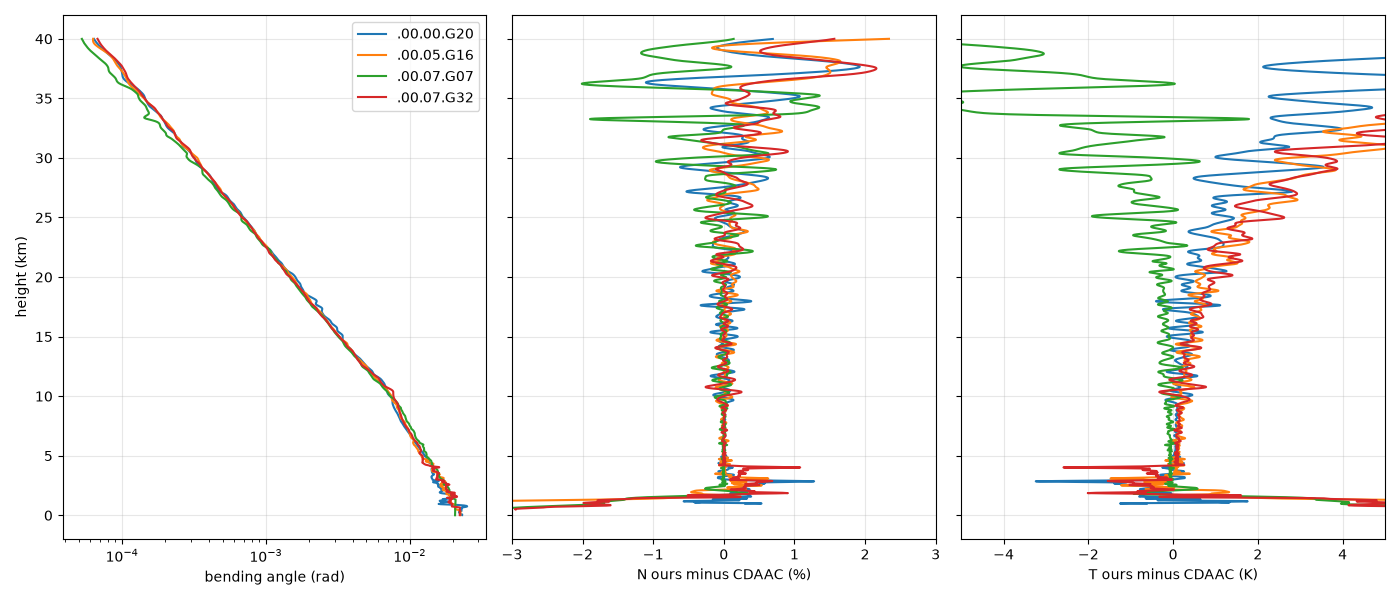

In [13]:
if __name__ == "__main__":
    compare("data", "atmPhs", "results.png")

## Run on COSMIC-2 (day 2024/001)
Ten GPS occultations, rising and setting. CDAAC tags two of them BAD (G19 and G28), they are not compared, our QC flags them too.


C2E1.2024.001.00.01.G11
  QC failed tests ours []   CDAAC bad flag 0
  lowest 0.0 km (CDAAC 0.0)   lat/lon/azim diff 0.040 0.052 0.016 deg
  tropopause cold point ours 17.56 km -82.8 C (CDAAC 17.57 -82.9)   WMO ours 17.46 km (CDAAC 17.45)
   0- 5 km  N diff  -1.01 %   T diff  +1.84 K
   5-10 km  N diff  -0.02 %   T diff  +0.11 K
  10-20 km  N diff  +0.01 %   T diff  +0.09 K
  20-30 km  N diff  +0.03 %   T diff  +0.50 K
  30-40 km  N diff  +0.26 %   T diff  +1.31 K

C2E1.2024.001.00.05.G19
  QC failed tests ours [1, 2, 6, 7]   CDAAC bad flag 1
  CDAAC tagged its own profile BAD, not compared

C2E1.2024.001.00.06.G32
  QC failed tests ours []   CDAAC bad flag 0
  lowest 0.0 km (CDAAC 0.2)   lat/lon/azim diff 0.009 0.005 0.000 deg
  tropopause cold point ours 17.86 km -85.5 C (CDAAC 17.87 -85.4)   WMO ours 17.80 km (CDAAC 17.80)
   0- 5 km  N diff  -2.11 %   T diff  +4.14 K
   5-10 km  N diff  -0.03 %   T diff  -0.03 K
  10-20 km  N diff  -0.01 %   T diff  -0.09 K
  20-30 km  N diff  -0.

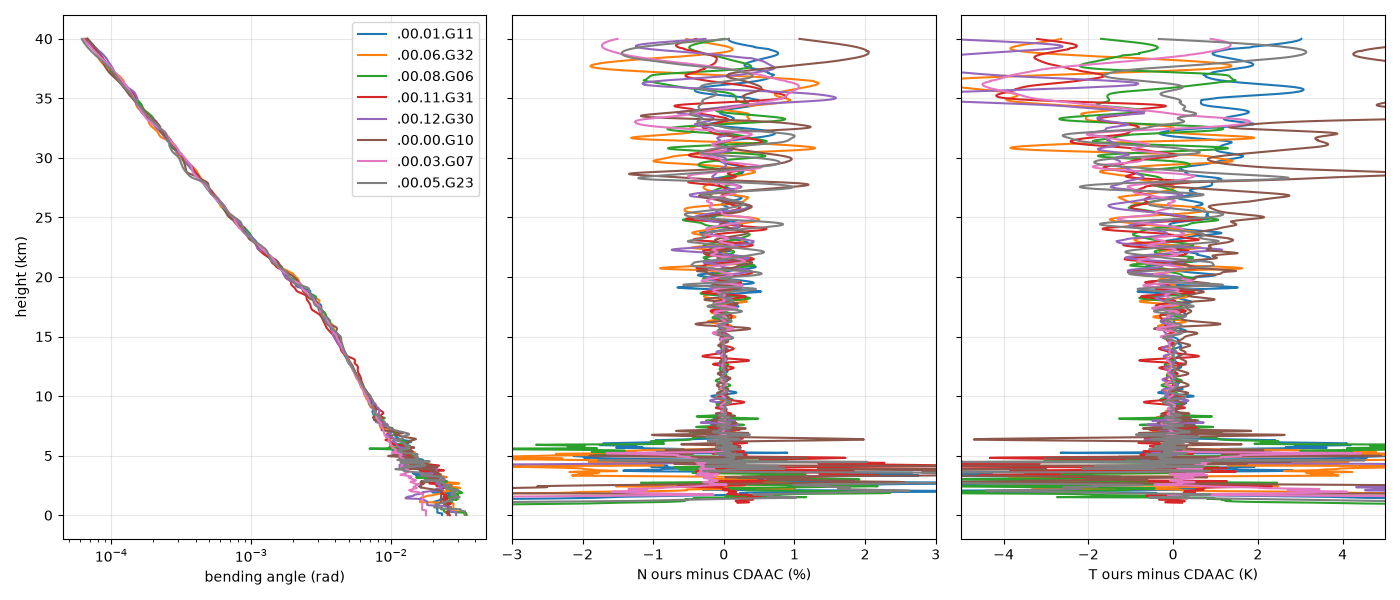

In [14]:
if __name__ == "__main__":
    compare("data_cosmic2", "conPhs", "results_cosmic2.png")

## Run on the ionosphere (COSMIC-1 ionPhs)
Eight profiles, electron density against the CDAAC `ionPrf` profile.

C001.2010.001.00.05.G24  peak height ours  232 km CDAAC  232 km   peak density ours 3.97e+10 CDAAC 4.84e+10 el/m3   median diff 120-450 km  -42.3 %
C001.2010.001.00.10.G05  peak height ours  226 km CDAAC  226 km   peak density ours 4.78e+10 CDAAC 5.35e+10 el/m3   median diff 120-450 km  -18.5 %
C001.2010.001.00.10.G12  peak height ours  217 km CDAAC  222 km   peak density ours 5.75e+10 CDAAC 6.37e+10 el/m3   median diff 120-450 km  -16.0 %
C001.2010.001.00.36.G13  peak height ours  251 km CDAAC  251 km   peak density ours 2.08e+11 CDAAC 2.12e+11 el/m3   median diff 120-450 km   -2.3 %
C001.2010.001.00.51.G20  peak height ours  256 km CDAAC  256 km   peak density ours 2.53e+11 CDAAC 2.59e+11 el/m3   median diff 120-450 km   -2.6 %
C001.2010.001.00.59.G32  peak height ours  237 km CDAAC  237 km   peak density ours 3.11e+11 CDAAC 3.14e+11 el/m3   median diff 120-450 km   -1.3 %
C001.2010.001.01.07.G11  peak height ours  235 km CDAAC  235 km   peak density ours 3.34e+11 CDAAC 3.40e+11 el/m

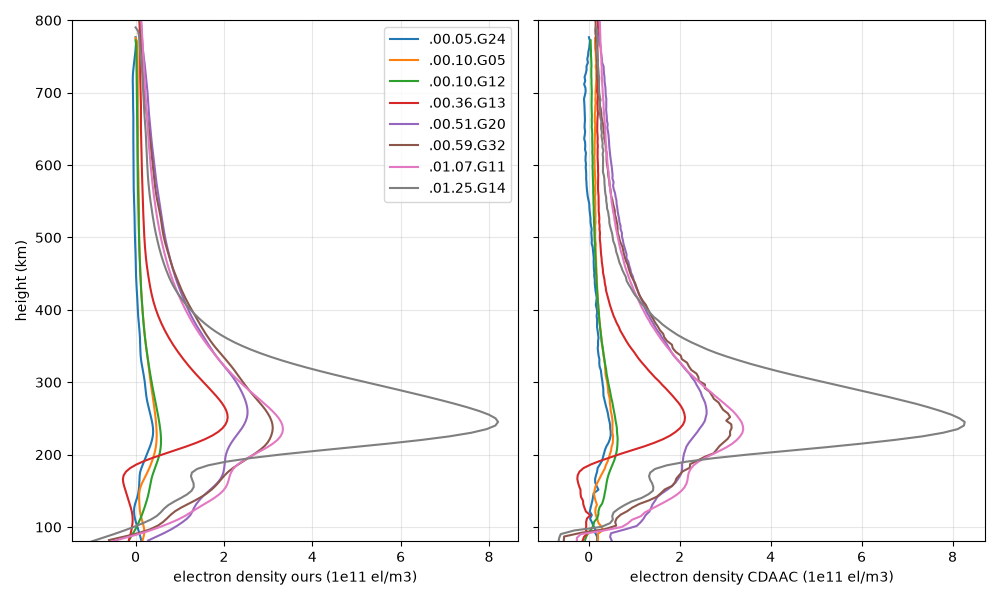

In [15]:
if __name__ == "__main__":
    compare_ionosphere("data_iono", "results_iono.png")